# Market Risk: Comparing VaR Models with Regulatory Backtests and Stress Tests

**Goal.** A risk manager must not only compute Value-at-Risk but prove that the model
works. This project runs four VaR models on a €100m multi-asset portfolio over ten years,
then puts them through the tests a regulator would apply.

| Question | Test |
|---|---|
| Does the model breach as often as it should? | Kupiec proportion of failures |
| Do breaches come in clusters? | Christoffersen independence |
| What capital multiplier would the regulator impose? | Basel traffic light (250 days) |
| Is the tail (ES) right? | Acerbi-Szekely Z2 |
| What happens in a crisis the data has not seen? | Historical and reverse stress tests |

**Data.** Ten years of synthetic daily returns with what makes real markets hard to model:
fat tails, volatility clustering, and a stress regime where correlations jump.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("varbt.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/14-market-risk-var-backtesting")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from varbt import (simulate_market, rolling_var_es, kupiec_pof, christoffersen, traffic_light, acerbi_szekely_z2,
                   z2_critical_value, SCENARIOS, stress_pnl, reverse_stress, ASSETS)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
returns = simulate_market(2500, seed=11)
exposures = pd.Series([40, 35, 15, 5, 5.0], index=ASSETS)          # EUR m
pnl = (returns * exposures).sum(axis=1)                              # daily P&L, EUR m
pd.DataFrame({"Exposure (EUR m)": exposures, "Daily vol (%)": returns.std() * 100, "Excess kurtosis": returns.kurt()}).round(2)

,Exposure (EUR m),Daily vol (%),Excess kurtosis
Equities,40.0,1.21,5.78
Govt bonds,35.0,0.36,8.95
Credit,15.0,0.25,9.65
USD/EUR,5.0,0.57,4.77
Commodities,5.0,1.53,6.70


## 1. The portfolio P&L

Calm years with occasional violent episodes. The excess kurtosis shows tails far fatter
than a normal distribution (whose excess kurtosis is 0).

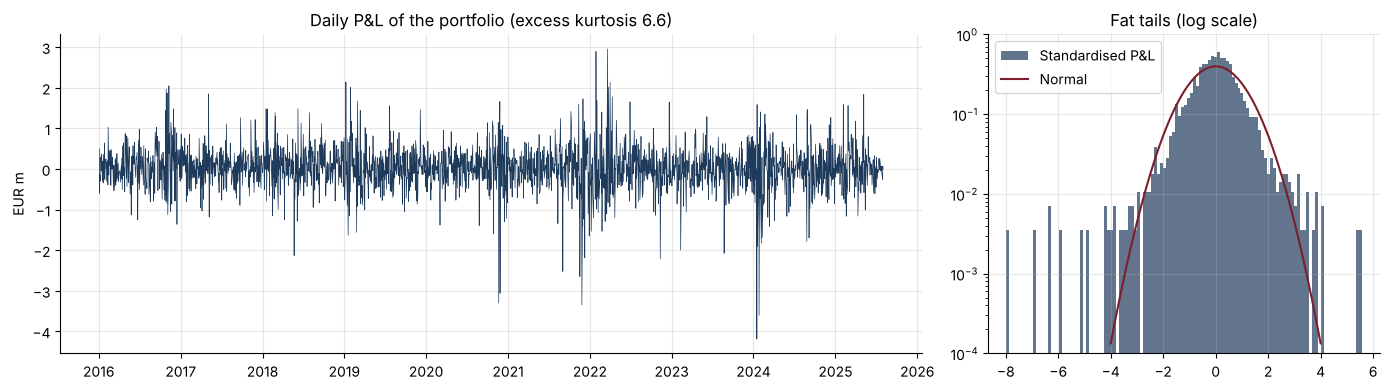

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].plot(pnl.index, pnl, color=NAVY, lw=0.5)
axes[0].set(title=f"Daily P&L of the portfolio (excess kurtosis {pnl.kurt():.1f})", ylabel="EUR m")
x = np.linspace(-4, 4, 200)
axes[1].hist((pnl - pnl.mean()) / pnl.std(), bins=120, density=True, color=NAVY, alpha=0.7, label="Standardised P&L")
axes[1].plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), color=BORDEAUX, label="Normal")
axes[1].set_yscale("log"); axes[1].set_ylim(1e-4, 1); axes[1].legend(); axes[1].set_title("Fat tails (log scale)")
plt.tight_layout(); plt.savefig("images/pnl.png", dpi=150); plt.show()

## 2. Four VaR models (99%, one day, 250-day window)

| Model | Idea | Weakness |
|---|---|---|
| Parametric normal | mean and standard deviation of the last 250 days | thin tails, slow |
| Historical simulation | 1% quantile of the last 250 P&Ls | slow to react to new volatility |
| EWMA (RiskMetrics) | volatility with exponential weights, λ = 0.94 | normal tails |
| Filtered historical (FHS) | past returns rescaled by today's volatility | needs a volatility model |

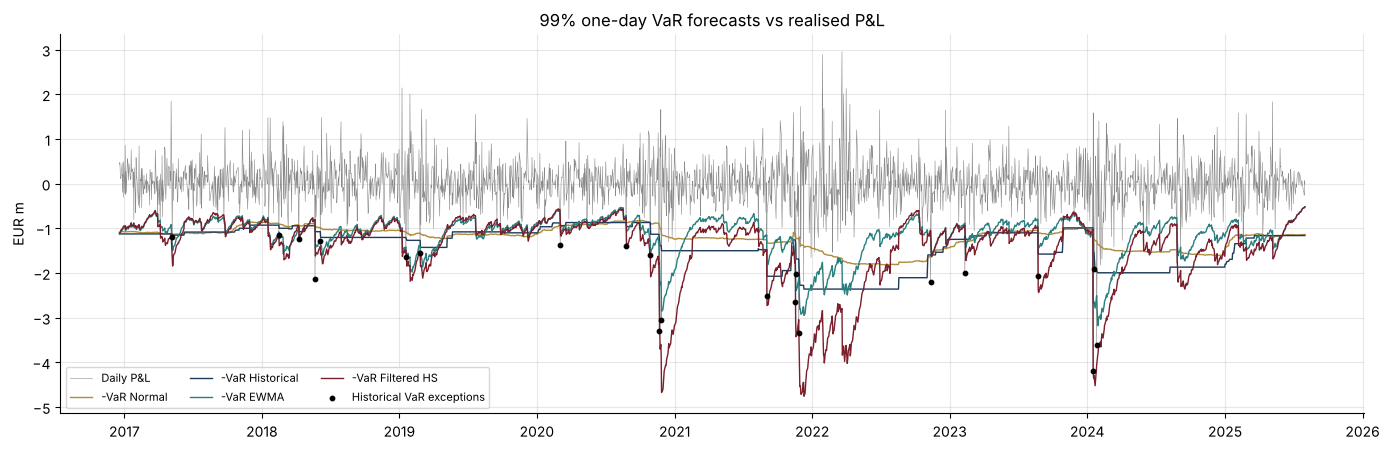

In [3]:
models = {"Normal": "normal", "Historical": "historical", "EWMA": "ewma", "Filtered HS": "fhs"}
forecasts = {name: rolling_var_es(pnl, m, alpha=0.99) for name, m in models.items()}
valid = forecasts["Normal"][0].notna()
P = pnl[valid]

fig, ax = plt.subplots(figsize=(14, 4.6))
ax.plot(P.index, P, color=GREY, lw=0.4, label="Daily P&L")
for (name, (v, _)), c in zip(forecasts.items(), [GOLD, NAVY, TEAL, BORDEAUX]):
    ax.plot(v[valid].index, -v[valid], color=c, lw=1, label=f"-VaR {name}")
hits = P < -forecasts["Historical"][0][valid]
ax.scatter(P.index[hits], P[hits], color="black", s=10, zorder=4, label="Historical VaR exceptions")
ax.set(ylabel="EUR m", title="99% one-day VaR forecasts vs realised P&L"); ax.legend(ncol=3, fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig("images/var_forecasts.png", dpi=150); plt.show()

## 3. Backtesting

Over $T$ days at 99%, about $0.01\,T$ exceptions are expected. **Kupiec** tests the count;
**Christoffersen** tests whether an exception today makes one tomorrow more likely (a
model that reacts too slowly produces clusters). The **traffic light** counts exceptions in
each 250-day window: green (0-4), yellow (5-9) or red (10+), with a capital multiplier from 3 to 4.

In [4]:
rows = []
zones = {}
for name, (v, e) in forecasts.items():
    exc = (P < -v[valid]).astype(int)
    lr, p_pof = kupiec_pof(exc.sum(), len(exc))
    ch = christoffersen(exc.values)
    rolling = exc.rolling(250).sum().dropna()
    zones[name] = rolling
    worst = int(rolling.max())
    rows.append({"Model": name, "Exceptions": exc.sum(), "Expected": round(0.01 * len(exc), 1),
                 "Kupiec p-value": p_pof, "Independence p-value": ch["p_ind"],
                 "Worst 250-day count": worst, "Worst zone": traffic_light(worst)[0],
                 "Share of time in green": (rolling <= 4).mean(), "Average VaR (EUR m)": v[valid].mean()})
bt = pd.DataFrame(rows).set_index("Model")
bt.style.format({"Kupiec p-value": "{:.3f}", "Independence p-value": "{:.3f}", "Share of time in green": "{:.0%}",
                 "Average VaR (EUR m)": "{:.2f}"})

,Exceptions,Expected,Kupiec p-value,Independence p-value,Worst 250-day count,Worst zone,Share of time in green,Average VaR (EUR m)
Model,,,,,,,,
Normal,38,22.500000,0.003,0.674,10,red,50%,1.21
Historical,22,22.500000,0.915,0.212,5,yellow,96%,1.40
EWMA,33,22.500000,0.038,0.509,6,yellow,69%,1.15
Filtered HS,30,22.500000,0.131,0.418,6,yellow,79%,1.42


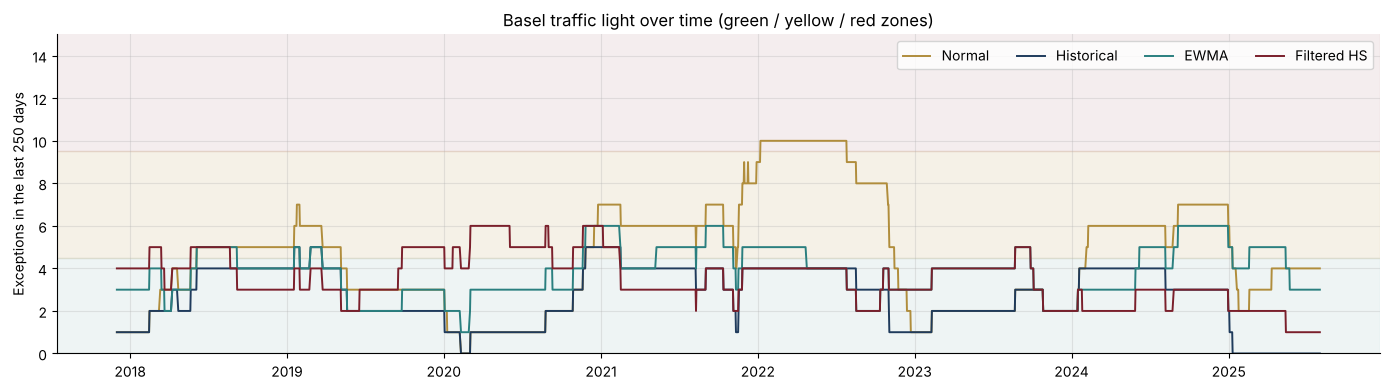

In [5]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.axhspan(0, 4.5, color=TEAL, alpha=0.08); ax.axhspan(4.5, 9.5, color=GOLD, alpha=0.12); ax.axhspan(9.5, 30, color=BORDEAUX, alpha=0.08)
for (name, z), c in zip(zones.items(), [GOLD, NAVY, TEAL, BORDEAUX]):
    ax.plot(z.index, z, color=c, lw=1.4, label=name)
ax.set(ylabel="Exceptions in the last 250 days", title="Basel traffic light over time (green / yellow / red zones)", ylim=(0, max(15, max(z.max() for z in zones.values()) + 1)))
ax.legend(ncol=4); plt.tight_layout(); plt.savefig("images/traffic_light.png", dpi=150); plt.show()

## 4. Backtesting Expected Shortfall (97.5%)

Under FRTB, market-risk capital is based on the 97.5% Expected Shortfall, the average loss
beyond the VaR. The Acerbi-Szekely $Z_2$ statistic is about 0 when ES is right and
negative when the losses beyond VaR are larger than predicted. The 5% critical value is
obtained by simulation under a correct model.

In [6]:
crit = z2_critical_value(alpha=0.975, n=len(P), n_sims=2000)
es_rows = []
for name, m in models.items():
    v, e = rolling_var_es(pnl, m, alpha=0.975)
    z2 = acerbi_szekely_z2(P.values, v[valid].values, e[valid].values, alpha=0.975)
    es_rows.append({"Model": name, "Z2": z2, "Verdict": "rejected" if z2 < crit else "not rejected"})
print(f"5% critical value of Z2: {crit:.3f}")
pd.DataFrame(es_rows).set_index("Model").round(3)

5% critical value of Z2: -0.229


,Z2,Verdict
Model,,
Normal,-0.415,rejected
Historical,-0.136,not rejected
EWMA,-0.382,rejected
Filtered HS,-0.211,not rejected


## 5. Stress tests

Backtests only use the past 10 years. Stress tests ask what a crisis like 2008, 2020 or
the 2022 rates shock would cost today, and the **reverse stress test** asks how severe a
scenario must be to cause a chosen loss (here €15m).

In [7]:
st = pd.DataFrame(SCENARIOS, index=ASSETS).T
st["Portfolio P&L (EUR m)"] = [stress_pnl(exposures.values, s) for s in SCENARIOS.values()]
st["In multiples of the 99% historical VaR"] = st["Portfolio P&L (EUR m)"] / forecasts["Historical"][0].iloc[-1]
st["Scale for a 15m loss"] = [reverse_stress(exposures.values, np.array(s), 15.0) for s in SCENARIOS.values()]
st.style.format({**{a: "{:+.0%}" for a in ASSETS}, "Portfolio P&L (EUR m)": "{:+.1f}",
                 "In multiples of the 99% historical VaR": "{:+.1f}", "Scale for a 15m loss": "{:.2f}x"})

,Equities,Govt bonds,Credit,USD/EUR,Commodities,Portfolio P&L (EUR m),In multiples of the 99% historical VaR,Scale for a 15m loss
2008 Lehman (Sep-Oct),-30%,+4%,-8%,+10%,-35%,-13.0,-11.2,1.15x
2020 Covid crash (Mar),-33%,+2%,-6%,+3%,-30%,-14.8,-12.7,1.02x
2022 rates shock,-20%,-17%,-12%,+12%,+25%,-13.9,-12.0,1.08x
Euro sovereign crisis 2011,-22%,-5%,-7%,-6%,-10%,-12.4,-10.7,1.21x


**Reading the stress table.** Each scenario costs 11 to 13 times the daily 99% VaR. The
Covid crash costs the most. The 2022 shock is different in nature: bonds and equities fall
*together*, so the bond holding that cushioned the portfolio in 2008 and 2020 becomes a
second source of loss. A scale close to 1 means each scenario sits near the €15m threshold.

## Conclusions
- **Normal VaR fails**: 38 exceptions against 22.5 expected (Kupiec p = 0.003), a red zone
  in the worst year, and a rejected ES. Fat tails are the problem.
- **EWMA reacts to volatility but keeps normal tails**: still too many exceptions (p = 0.04)
  and a rejected ES.
- **Historical and filtered historical simulation pass** the count, independence and ES
  tests on this sample. FHS reacts faster to volatility changes, at a similar average VaR.
- Stress tests show losses of 11 to 13 times the VaR and correlation breakdowns that no
  backtest on the past ten years can reveal.
- **Next steps:** stressed VaR (Basel 2.5), FRTB liquidity horizons, P&L attribution test.